In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Column Names
columns = [
    "mpg", "cylinders", "displacement",
    "horsepower", "weight", "acceleration",
    "model_year", "origin", "car_name"
]

# Load Dataset
df = pd.read_csv(
    url,
    sep=r"\s+",
    names=columns,
    na_values="?",
    quotechar='"'
)

# Display Dataset
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [3]:
# Select Input and Target
data = df[["displacement", "mpg"]].copy()

# Remove Missing Values
data = data.dropna()

# Display Information
print("Dataset Shape:", data.shape)
print("\nMissing Values:")
print(data.isnull().sum())

# Display First 5 Rows
data.head()

Dataset Shape: (398, 2)

Missing Values:
displacement    0
mpg             0
dtype: int64


,displacement,mpg
0,307.0,18.0
1,350.0,15.0
2,318.0,18.0
3,304.0,16.0
4,302.0,17.0


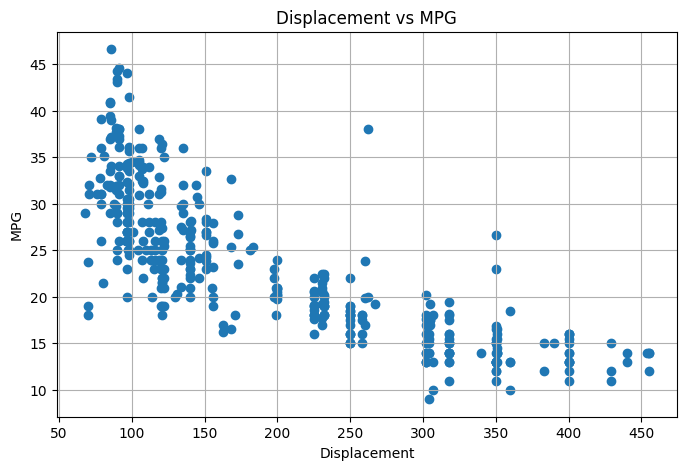

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(data["displacement"], data["mpg"])

plt.xlabel("Displacement")
plt.ylabel("MPG")
plt.title("Displacement vs MPG")

plt.grid(True)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select Input and Target
X = data[["displacement"]].values
y = data["mpg"].values

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create Polynomial Features (Degree 2)
X_train_poly = np.column_stack([
    X_train[:, 0],
    X_train[:, 0] ** 2
])

X_test_poly = np.column_stack([
    X_test[:, 0],
    X_test[:, 0] ** 2
])

# Scale Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

# Add Bias Column
X_train_final = np.column_stack([
    np.ones(len(X_train_scaled)),
    X_train_scaled
])

X_test_final = np.column_stack([
    np.ones(len(X_test_scaled)),
    X_test_scaled
])

print("Training Data:", X_train_final.shape)
print("Testing Data:", X_test_final.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (318, 3)
Testing Data: (80, 3)
Training Target: (318,)
Testing Target: (80,)


In [6]:
# Initialize Model Parameters
theta = np.zeros(X_train_final.shape[1])

# Learning Rate
learning_rate = 0.01

# Number of Epochs
epochs = 1000

# Momentum Parameter
beta = 0.9

# Cost Function (MSE)
def compute_cost(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    return np.mean(errors ** 2)

# Gradient Calculation
def compute_gradient(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    gradient = (2 / len(y)) * (X.T @ errors)
    return gradient

print("Initial Weights:", theta)
print("Initial Cost:", compute_cost(X_train_final, y_train, theta))

Initial Weights: [0. 0. 0.]
Initial Cost: 620.0422012578616


In [7]:
# Initialize Parameters
theta_gd = np.zeros(X_train_final.shape[1])
velocity = np.zeros_like(theta_gd)

gd_loss_history = []

# Gradient Descent with Momentum
for epoch in range(epochs):

    # Calculate Gradient
    gradient = compute_gradient(
        X_train_final,
        y_train,
        theta_gd
    )

    # Update Momentum
    velocity = beta * velocity + gradient

    # Update Weights
    theta_gd = theta_gd - learning_rate * velocity

    # Calculate Loss
    loss = compute_cost(
        X_train_final,
        y_train,
        theta_gd
    )

    gd_loss_history.append(loss)

print("Training Completed!")
print("Final Weights:", theta_gd)
print("Final Training MSE:", gd_loss_history[-1])

Training Completed!
Final Weights: [ 23.6081761  -14.00280085   7.80986577]
Final Training MSE: 19.97323380088107


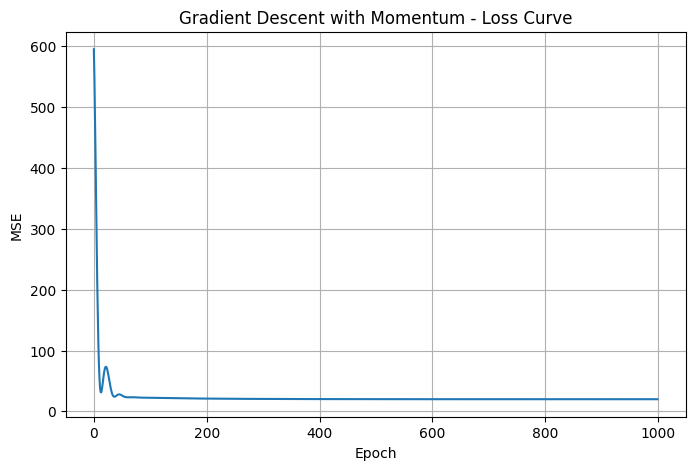

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(gd_loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent with Momentum - Loss Curve")

plt.grid(True)
plt.show()

In [9]:
from sklearn.metrics import mean_squared_error, r2_score

# Predictions on Test Data
y_pred = X_test_final @ theta_gd

# Evaluation Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Gradient Descent with Momentum Results")
print("---------------------------------------")
print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R2 Score:", r2)

Gradient Descent with Momentum Results
---------------------------------------
Test MSE: 15.122587072315577
Test RMSE: 3.8887770664201846
Test R2 Score: 0.7187355901269632


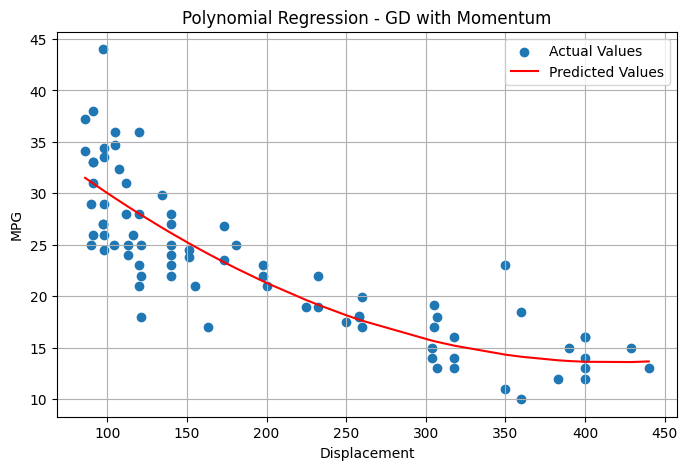

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test[:, 0], y_test, label="Actual Values")

# Sort values for a smooth prediction curve
sorted_indices = np.argsort(X_test[:, 0])

plt.plot(
    X_test[sorted_indices, 0],
    y_pred[sorted_indices],
    color="red",
    label="Predicted Values"
)

plt.xlabel("Displacement")
plt.ylabel("MPG")
plt.title("Polynomial Regression - GD with Momentum")
plt.legend()
plt.grid(True)
plt.show()